# Order picking

A warehouse has a morning batch of customer orders and a few trolleys. Each trolley carries a set of
buckets, and an order gets its own buckets because two orders never share one. A picker walks the
aisles, collects items, and returns to the start. The question is **which trolley picks which item, and
in what order**, so that everything fits, orders stay together, and the walking stays short.

Those goals pull against each other. The shortest walk can spread an order over several trolleys, and
those parts then have to be merged at packing.

In this notebook you will:

1. describe a batch of orders as Python objects,
2. solve it and draw each trolley's path through the aisles,
3. check the result yourself, without trusting the solver's score,
4. change how much a split order costs and watch orders break apart,
5. remove trolleys and see which rule gives way,
6. add a rush order to a running plan and restart the search from it.

Requires Python 3.11+: `pip install optimaru matplotlib`

In [1]:
import math
import re

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Rectangle

from optimaru import order_picking as op
from optimaru.order_picking import constraints as rules
from optimaru.order_picking.models import (
    LocationModel, OrderModel, OrderPickingRequest, ProductModel, TrolleyModel, solve_request,
    with_initial_solution,
)

COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, MUTED = "#52514e", "#898781"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "xtick.color": MUTED, "ytick.color": MUTED,
    "grid.color": "#e1e0d9", "grid.linewidth": 0.8, "legend.frameon": False, "font.size": 10,
})

## 1. Describe the batch

This use case has a fixed floor plan: five shelving columns `A` to `E`, three shelving rows `1` to `3`,
two sides per shelving, and positions `0` to `10` along a side. A location is one such address.

| Object | What it holds |
| --- | --- |
| `LocationModel` | column, shelving row, side and position along the side |
| `ProductModel` | one order item: volume in cm³ and where it is stored |
| `OrderModel` | an order id and its items |
| `TrolleyModel` | a trolley: number of buckets, bucket capacity in cm³, start location |
| `OrderPickingRequest` | trolleys, orders, the time limit and the seed |

Here is a fictional morning: 12 orders drawn from a catalog of 60 products, and 6 trolleys with 4
buckets each. All trolleys start at the same corner.

In [2]:
BUCKET_CAPACITY = 48_000
BUCKETS_PER_TROLLEY = 4
ORDERS = 12
START = LocationModel(column="A", shelving_row=1, side="LEFT", row=0)

rng = np.random.default_rng(11)
catalog = []
for i in range(60):
    catalog.append(dict(
        id=f"SKU-{i:02d}",
        volume=int(rng.integers(1_500, 16_000)),
        location=LocationModel(
            column="ABCDE"[int(rng.integers(5))], shelving_row=int(rng.integers(1, 4)),
            side=["LEFT", "RIGHT"][int(rng.integers(2))], row=int(rng.integers(0, 11)),
        ),
    ))

orders = []
for number in range(1, ORDERS + 1):
    size = int(rng.integers(6, 14))
    picked = rng.choice(len(catalog), size=size, replace=False)
    orders.append(OrderModel(id=f"O{number}", items=[ProductModel(**catalog[i]) for i in picked]))


def make_request(trolley_count=6, timelimit=4.0, random_seed=42):
    """A fresh request. Trolley colors follow the trolley number in every chart."""
    trolleys = [
        TrolleyModel(id=f"T{k + 1}", bucket_count=BUCKETS_PER_TROLLEY, bucket_capacity=BUCKET_CAPACITY,
                     location=START)
        for k in range(trolley_count)
    ]
    return OrderPickingRequest(timelimit=timelimit, random_seed=random_seed, trolleys=trolleys, orders=orders)


def buckets_needed(volume):
    """Buckets are whole and never shared, so each order rounds its own volume up."""
    return math.ceil(volume / BUCKET_CAPACITY)


request = make_request()
needed = sum(buckets_needed(sum(item.volume for item in order.items)) for order in orders)
print(f"{len(orders)} orders, {sum(len(order.items) for order in orders)} picks, {len(request.trolleys)} trolleys")
print(f"buckets needed if no order is split: {needed}, buckets available: "
      f"{len(request.trolleys) * BUCKETS_PER_TROLLEY}")

12 orders, 108 picks, 6 trolleys
buckets needed if no order is split: 23, buckets available: 24


Buckets are tight on purpose. Each part of a split order rounds up on its own, so a split can use more
buckets than the order needs, and this batch has little room to waste.

### The floor plan

Shelvings are 2 m wide and 10 m tall, with 3 m of aisle between them. This function turns a location into
metres on the floor, and walks from one location to another the way the score measures distance. On
one shelving row, a walk can cross only at the top or bottom end of the shelvings, so it takes the shorter
way round. Neighbouring faces of one aisle are the exception: the picker crosses the aisle directly.

Drawing a path means re-deriving distance, so the next cell compares every leg to the solver's own
`calculate_distance` before any chart uses it.

In [3]:
SHELF_WIDTH, SHELF_HEIGHT, AISLE = 2, 10, 3


def on_floor(location):
    """(x, y) in metres, with y growing down the plan as it does in the warehouse."""
    x = "ABCDE".index(location.column) * (SHELF_WIDTH + AISLE) + (SHELF_WIDTH if location.side == "RIGHT" else 0)
    return x, (location.shelving_row - 1) * (SHELF_HEIGHT + AISLE) + location.row


def walk(start, end):
    """Corner points of the walk between two locations."""
    (x0, y0), (x1, y1) = on_floor(start), on_floor(end)
    if start.shelving_row != end.shelving_row:
        upper = min(start.shelving_row, end.shelving_row) - 1
        corridor = upper * (SHELF_HEIGHT + AISLE) + SHELF_HEIGHT + AISLE / 2
        return [(x0, y0), (x0, corridor), (x1, corridor), (x1, y1)]
    if start.column == end.column and start.side == end.side:
        return [(x0, y0), (x1, y1)]
    if abs(x0 - x1) == AISLE:
        return [(x0, y0), (x0, y1), (x1, y1)]
    top = (start.shelving_row - 1) * (SHELF_HEIGHT + AISLE)
    round_top = start.row + end.row
    round_bottom = 2 * SHELF_HEIGHT - start.row - end.row
    corridor = top if round_top < round_bottom else top + SHELF_HEIGHT
    return [(x0, y0), (x0, corridor), (x1, corridor), (x1, y1)]


def walked(points):
    return sum(abs(a[0] - b[0]) + abs(a[1] - b[1]) for a, b in zip(points, points[1:]))


places = [item["location"] for item in catalog] + [START]
mismatches = sum(
    walked(walk(a, b)) != op.calculate_distance(a.to_core(), b.to_core())
    for a in places for b in places
)
print(f"legs compared with calculate_distance: {len(places) ** 2}, mismatches: {mismatches}")

legs compared with calculate_distance: 3721, mismatches: 0


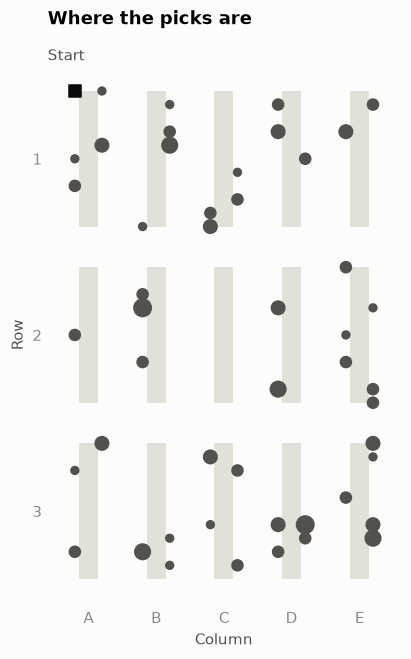

In [4]:
def draw_floor(ax):
    """The shelvings. Rectangles are drawn narrower than the real 2 m so that paths stay visible."""
    for column in range(5):
        for row in range(3):
            ax.add_patch(Rectangle(
                (column * (SHELF_WIDTH + AISLE) + 0.3, row * (SHELF_HEIGHT + AISLE)), SHELF_WIDTH - 0.6, SHELF_HEIGHT,
                facecolor="#e1e0d9", edgecolor="none", zorder=0,
            ))
    ax.set_xlim(-2, 24)
    ax.set_ylim(38, -2)
    ax.set_aspect("equal")
    ax.set_xticks([column * 5 + 1 for column in range(5)], list("ABCDE"))
    ax.set_yticks([row * 13 + 5 for row in range(3)], [1, 2, 3])
    ax.tick_params(length=0)
    for side in ax.spines.values():
        side.set_visible(False)


counts = {}
for order in orders:
    for item in order.items:
        point = on_floor(item.location)
        counts[point] = counts.get(point, 0) + 1

fig, ax = plt.subplots(figsize=(4.8, 6.4))
draw_floor(ax)
ax.scatter([p[0] for p in counts], [p[1] for p in counts], s=[26 * n for n in counts.values()], color=INK, zorder=2)
start_x, start_y = on_floor(START)
ax.scatter(start_x, start_y, marker="s", s=70, color="#0b0b0b", zorder=3)
ax.annotate("Start", (start_x, start_y), xytext=(-2, -2.0), ha="left", va="bottom", textcoords="data", color=INK)
ax.set_title("Where the picks are", pad=26)
ax.set(xlabel="Column", ylabel="Row")
plt.show()

Larger dots are locations picked by more orders.

## 2. Solve it

`solve_request` returns the routes, the walking distance per trolley and the score. The score has two
levels, compared in order:

- **hard**: minus the buckets the trolleys are short of. `0` means every trolley has room for its orders.
- **soft**: minus the metres walked, including the way back to the start, and minus 1000 for every
  (order, trolley) pair. An order on one trolley costs 1000, and on three trolleys costs 3000.

So with default weights, the solver would walk up to 1000 m more to keep one order from splitting.

In [5]:
solution = solve_request(request)

print("feasible:", solution.feasible)
print("score   :", solution.score)
print(f"walking : {solution.total_distance} m")
print(f"(order, trolley) pairs: {solution.order_split_count} for {len(orders)} orders")
for trolley, stops in solution.routes.items():
    carried = sorted({stop.order_id for stop in stops}, key=lambda order_id: int(order_id[1:]))
    print(f"{trolley}: {len(stops)} picks, {solution.distance_by_trolley[trolley]} m, orders {' '.join(carried)}")

feasible: True
score   : 0hard/-12962soft
walking : 962 m
(order, trolley) pairs: 12 for 12 orders
T1: 19 picks, 154 m, orders O6 O10
T2: 21 picks, 174 m, orders O3 O4
T3: 23 picks, 170 m, orders O1 O2 O12
T4: 12 picks, 138 m, orders O9
T5: 18 picks, 170 m, orders O7 O11
T6: 15 picks, 156 m, orders O5 O8


### The picking paths

This is what each picker would be handed: one floor plan per trolley, with the path through the aisles
and a dot at each pick. A path starts and ends at the black square. Walking it in the opposite direction
costs the same.

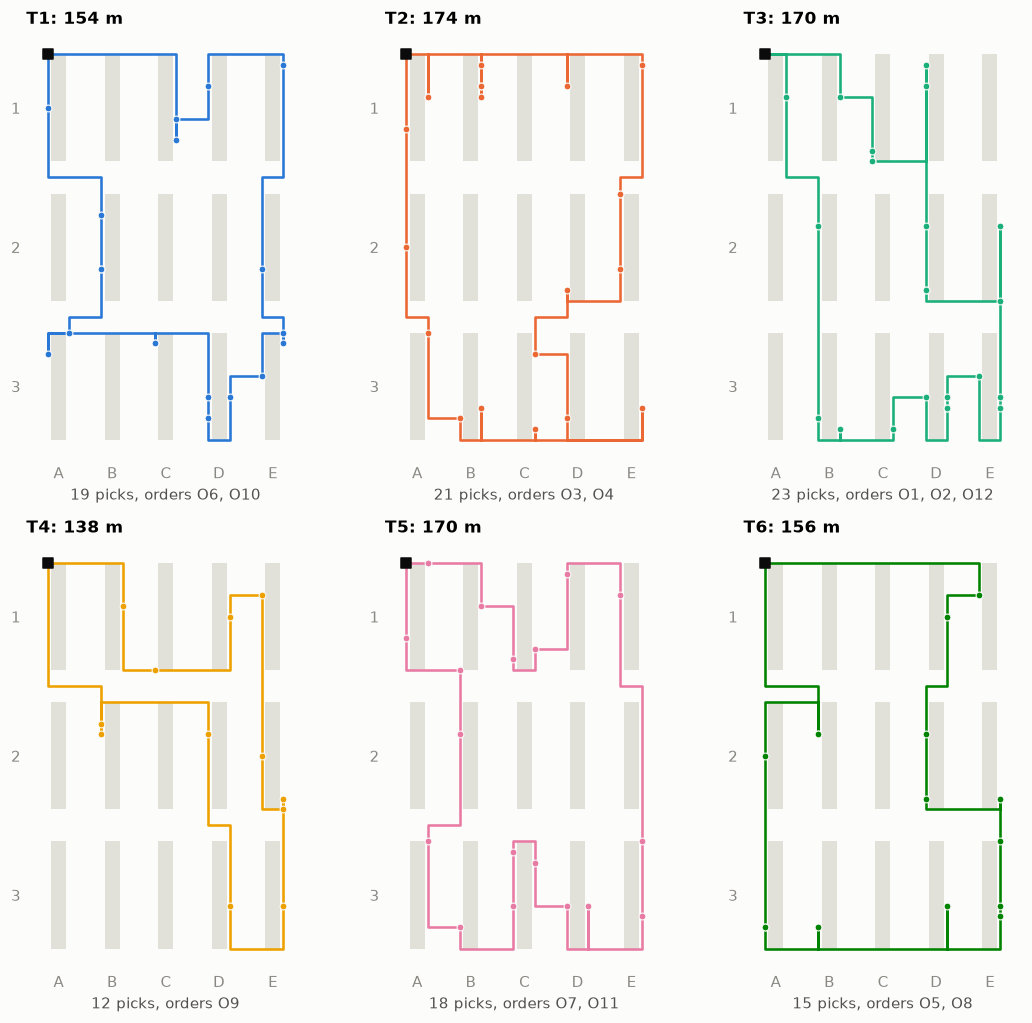

In [6]:
def trolley_path(stops):
    """Every corner of one trolley's round trip, from the start and back."""
    locations = [START, *(stop.location for stop in stops), START]
    corners = [on_floor(START)]
    for a, b in zip(locations, locations[1:]):
        corners += walk(a, b)[1:]
    return corners


def draw_trolley(ax, stops, color):
    draw_floor(ax)
    corners = trolley_path(stops)
    ax.plot([p[0] for p in corners], [p[1] for p in corners], color=color, linewidth=1.7,
            solid_joinstyle="round", zorder=1)
    picks = [on_floor(stop.location) for stop in stops]
    ax.scatter([p[0] for p in picks], [p[1] for p in picks], s=20, color=color, edgecolor="#fcfcfb",
               linewidth=0.7, zorder=2)
    ax.scatter(*on_floor(START), marker="s", s=44, color="#0b0b0b", zorder=3)


fig, axes = plt.subplots(2, 3, figsize=(10, 9.4))
for k, (ax, trolley) in enumerate(zip(axes.flat, request.trolleys)):
    stops = solution.routes[trolley.id]
    draw_trolley(ax, stops, COLORS[k])
    carried = sorted({stop.order_id for stop in stops}, key=lambda order_id: int(order_id[1:]))
    ax.set_title(f"{trolley.id}: {solution.distance_by_trolley[trolley.id]} m", fontsize=11)
    ax.set_xlabel(f"{len(stops)} picks, orders {', '.join(carried)}", color=INK)
plt.tight_layout()
plt.show()

## 3. Check the result yourself

The routes hold everything needed to verify the plan with no solver code: each pick is on one trolley,
each order's buckets fit on its trolley, and each trolley walks the distance reported. Walking is
measured here from the path drawn above.

Each block in the chart is one order on one trolley, and its width is the number of buckets it takes.

every pick routed exactly once: True
buckets short per trolley     : {'T1': 0, 'T2': 0, 'T3': 0, 'T4': 0, 'T5': 0, 'T6': 0}
distances that do not match   : []


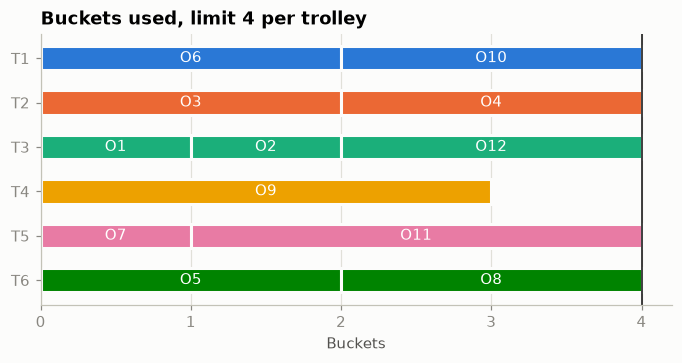

In [7]:
wanted = sorted(f"{order.id}-{i}" for order in orders for i in range(len(order.items)))
routed = sorted(stop.pick_task_id for stops in solution.routes.values() for stop in stops)

short, wrong_distance, blocks = {}, [], {}
for trolley in request.trolleys:
    stops = solution.routes[trolley.id]
    volume = {}
    for stop in stops:
        volume[stop.order_id] = volume.get(stop.order_id, 0) + stop.volume
    blocks[trolley.id] = {order_id: buckets_needed(total) for order_id, total in volume.items()}
    short[trolley.id] = max(0, sum(blocks[trolley.id].values()) - trolley.bucket_count)
    if walked(trolley_path(stops)) != solution.distance_by_trolley[trolley.id]:
        wrong_distance.append(trolley.id)

print("every pick routed exactly once:", routed == wanted)
print("buckets short per trolley     :", short)
print("distances that do not match   :", wrong_distance)

fig, ax = plt.subplots(figsize=(7.4, 3.2))
for row, trolley in enumerate(request.trolleys):
    left = 0
    for order_id, width in sorted(blocks[trolley.id].items(), key=lambda block: int(block[0][1:])):
        ax.barh(row, width, left=left, height=0.55, color=COLORS[row], edgecolor="#fcfcfb", linewidth=2)
        ax.text(left + width / 2, row, order_id, ha="center", va="center", color="white")
        left += width
ax.axvline(BUCKETS_PER_TROLLEY, color="#0b0b0b", linewidth=1)
ax.set_yticks(range(len(request.trolleys)), [t.id for t in request.trolleys])
ax.invert_yaxis()
ax.set_xticks(range(BUCKETS_PER_TROLLEY + 1))
ax.set(title=f"Buckets used, limit {BUCKETS_PER_TROLLEY} per trolley", xlabel="Buckets")
ax.grid(True, axis="x")
plt.show()

## 4. Change the rules, not the solver

Every rule is a plugin. `list_constraints()` shows what ships with this use case, and `solve_request` takes
the list you want through `constraints=`. Only listed constraints are scored.

In [8]:
for name in op.list_constraints():
    print(name)

required_number_of_buckets
minimize_distance_from_previous_pick_task
minimize_distance_from_last_pick_task_to_path_origin
minimize_order_split_by_trolley


Is 1000 m per split the right price? If the packing bench can merge orders cheaply, a lower weight may
save the pickers real walking. `minimize_order_split_by_trolley` sets that price, so this run lowers its
weight to 10.

Compare runs on the same path. A solve without `constraints=` also uses a move that gathers an order onto
one trolley, and that move does not run when you pass a constraint list. Both runs here pass a list.

Each grid has one row per order. A number is how many picks of that order ride on that trolley, so a row
with several filled cells is a split order. Trolley numbers do not carry over from one grid to the other.

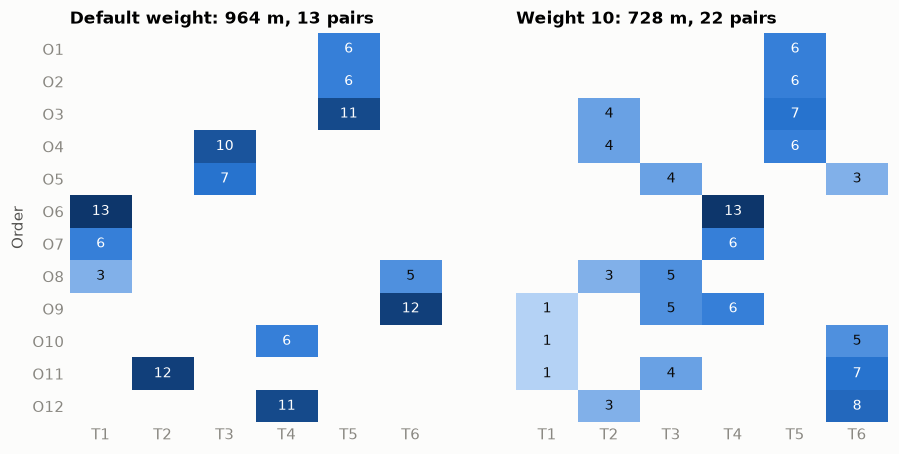

default weight: 0hard/-13964soft, 964 m walked, 13 (order, trolley) pairs for 12 orders
weight 10: 0hard/-948soft, 728 m walked, 22 (order, trolley) pairs for 12 orders


In [9]:
LOW_WEIGHT = 10
walking = [
    rules.required_number_of_buckets,
    rules.minimize_distance_from_previous_pick_task,
    rules.minimize_distance_from_last_pick_task_to_path_origin,
]

full_price = solve_request(make_request(timelimit=3), constraints=rules.get_constraints())
low_price = solve_request(
    make_request(timelimit=3), constraints=[*walking, rules.MinimizeOrderSplitByTrolley(weight=LOW_WEIGHT)],
)


def picks_grid(result):
    grid = np.zeros((len(orders), len(result.routes)), dtype=int)
    for column, stops in enumerate(result.routes.values()):
        for stop in stops:
            grid[int(stop.order_id[1:]) - 1, column] += 1
    return grid


blues = LinearSegmentedColormap.from_list("blue", ["#cde2fb", "#2a78d6", "#0d366b"])
fig, axes = plt.subplots(1, 2, figsize=(9.6, 4.6), sharey=True)
for ax, result, title in ((axes[0], full_price, "Default weight"), (axes[1], low_price, f"Weight {LOW_WEIGHT}")):
    grid = picks_grid(result)
    ax.imshow(np.ma.masked_equal(grid, 0), cmap=blues, vmin=0, vmax=grid.max(), aspect="auto")
    for (row, column), picks in np.ndenumerate(grid):
        if picks:
            ax.text(column, row, picks, ha="center", va="center", fontsize=9,
                    color="white" if picks > 5 else "#0b0b0b")
    ax.set_xticks(range(grid.shape[1]), list(result.routes))
    ax.set_yticks(range(len(orders)), [order.id for order in orders])
    ax.tick_params(length=0)
    for side in ax.spines.values():
        side.set_visible(False)
    ax.set_title(f"{title}: {result.total_distance} m, {result.order_split_count} pairs", fontsize=11)
axes[0].set_ylabel("Order")
plt.show()

for label, result in (("default weight", full_price), (f"weight {LOW_WEIGHT}", low_price)):
    print(f"{label}: {result.score}, {result.total_distance} m walked, "
          f"{result.order_split_count} (order, trolley) pairs for {len(orders)} orders")

Scores from two different weights are not comparable, so compare the metres and the pairs. Both runs stop
on the clock, so these are the best found in that time rather than proven optima.

## 5. Fewer trolleys

Picks cannot be left out in this use case: every pick rides on a trolley. When there are too few buckets,
nothing else can give way, so the shortfall appears on the hard level and the plan is infeasible. Walking
can look better at the same time, which is why hard is compared first. Do not read a shorter walk on an
infeasible plan as an improvement.

Bars past the black line are the buckets that do not exist.

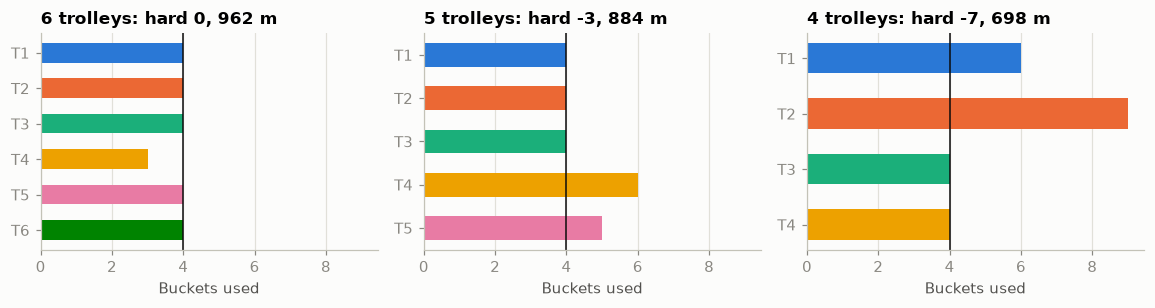

In [10]:
TROLLEY_COUNTS = [6, 5, 4]
fig, axes = plt.subplots(1, 3, figsize=(10.6, 2.9), sharex=True)
for ax, count in zip(axes, TROLLEY_COUNTS):
    fewer = make_request(trolley_count=count, timelimit=2)
    result = solve_request(fewer)
    for row, trolley in enumerate(fewer.trolleys):
        volume = {}
        for stop in result.routes[trolley.id]:
            volume[stop.order_id] = volume.get(stop.order_id, 0) + stop.volume
        ax.barh(row, sum(buckets_needed(total) for total in volume.values()), height=0.55, color=COLORS[row])
    ax.axvline(BUCKETS_PER_TROLLEY, color="#0b0b0b", linewidth=1)
    ax.set_yticks(range(count), [t.id for t in fewer.trolleys])
    ax.invert_yaxis()
    hard = re.match(r"-?\d+", result.score).group()
    ax.set_title(f"{count} trolleys: hard {hard}, {result.total_distance} m", fontsize=11)
    ax.set_xlabel("Buckets used")
    ax.grid(True, axis="x")
plt.tight_layout()
plt.show()

## 6. Keep working from an existing plan

### A rush order

A new order arrives after the plan is made. `with_initial_solution` turns a solution into each trolley's
`initial_route`. Add the order to the request, and the existing routes stay as the starting point while
construction places only the new picks. The search can then move anything.

A pick task id is `<order id>-<item position>`, so keep each order's items in the order they were solved
in. Add new orders at the end, and do not reorder the old ones.

Pick a new `random_seed` for the restart, for the reason in the next section.

In [11]:
rush_items = [ProductModel(**catalog[i]) for i in (3, 17, 41)]

replan = with_initial_solution(request, solution)
replan.orders = [*replan.orders, OrderModel(id="RUSH", items=rush_items)]
replan.timelimit = 3
replan.random_seed = 43

updated = solve_request(replan)


def stop_ids(result):
    return {trolley: [stop.pick_task_id for stop in stops] for trolley, stops in result.routes.items()}


old, new = stop_ids(solution), stop_ids(updated)
print("score:", updated.score)
print("rush order on:", [t for t, stops in updated.routes.items() if any(s.order_id == "RUSH" for s in stops)])
print(f"walking: {solution.total_distance} m before, {updated.total_distance} m after")
print("trolleys with a changed route:", [t for t in old if old[t] != new[t]])

score: 0hard/-13970soft
rush order on: ['T4']
walking: 962 m before, 970 m after
trolleys with a changed route: ['T4']


### More search, in rounds

`with_initial_solution` also lets you spend more time in rounds, each continuing from the last answer.
These rounds start from a plan with no search in it: a `timelimit` of 0 runs construction only.

**Give each round its own `random_seed`.** The same start with the same seed repeats the same search, so
that round has nothing new to find. A same-seed run can still improve for a while, because each better
answer is a new start. The first round that finds nothing ends it: the next round has the same start and
the same seed, and so does every round after.

A flat line is a result to check, not to accept. It can mean the search is stuck, or that nothing better
exists within reach. The horizontal line is a separate, longer solve from scratch: if a run stops above
it, the rounds stalled early.

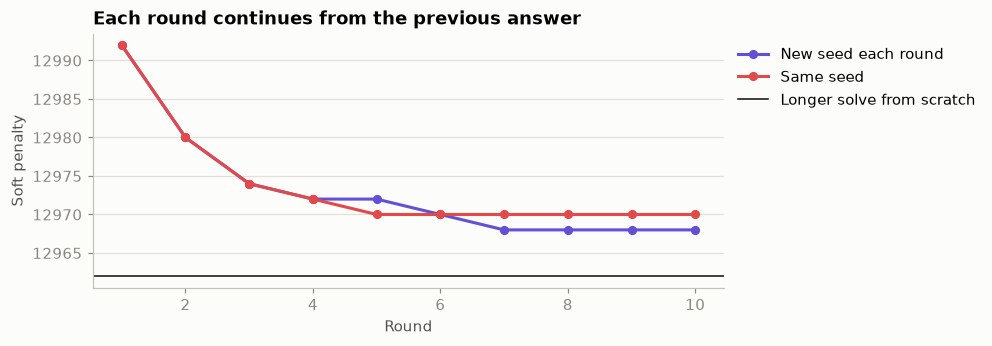

construction only: 15060
after 10 rounds: new seed 12968, same seed 12970
longer solve from scratch: 12962


In [12]:
ROUNDS = 10
ROUND_SECONDS = 0.005


def penalty(result):
    """The soft level at default weights, from the metres and pairs in the response."""
    return result.total_distance + 1000 * result.order_split_count


def search_in_rounds(start, change_seed):
    history, current = [], start
    next_request = make_request(timelimit=ROUND_SECONDS, random_seed=100)
    for round_number in range(ROUNDS):
        next_request = with_initial_solution(next_request, current)
        if change_seed:
            next_request.random_seed = 100 + round_number
        current = solve_request(next_request)
        history.append(penalty(current))
    return history


constructed = solve_request(make_request(timelimit=0))
new_seed = search_in_rounds(constructed, change_seed=True)
same_seed = search_in_rounds(constructed, change_seed=False)
long_solve = solve_request(make_request(timelimit=3, random_seed=7))

fig, ax = plt.subplots(figsize=(7.4, 3))
rounds = range(1, ROUNDS + 1)
ax.plot(rounds, new_seed, color=COLORS[6], linewidth=2, marker="o", markersize=5, label="New seed each round")
ax.plot(rounds, same_seed, color=COLORS[7], linewidth=2, marker="o", markersize=5, label="Same seed")
ax.axhline(penalty(long_solve), color="#0b0b0b", linewidth=1, label="Longer solve from scratch")
ax.set(title="Each round continues from the previous answer", xlabel="Round", ylabel="Soft penalty")
ax.grid(True, axis="y")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

print(f"construction only: {penalty(constructed)}")
print(f"after {ROUNDS} rounds: new seed {new_seed[-1]}, same seed {same_seed[-1]}")
print(f"longer solve from scratch: {penalty(long_solve)}")

## Next steps

- `SolverConfig` in `optimaru.order_picking` holds the search options, and `solve_request` accepts them through
  `solver_parameters`.
- `use-cases/order-picking/README.md` covers starting from a solution and how to add your own moves
  and constraints in C++.
- For routes on a road map rather than through aisles, see `vehicle-routing.ipynb`.